# Mining comparison on CSCAS (plan 7.6)

Does the mining principle matter, given the same alert groups, input attributes and downstream model?
Walk-forward over CSCAS (baseline split, γ = 0.05, 20 steps), Base(5) alone (`none`) vs. Base(5) + each method's features:

| Arm | Principle |
|---|---|
| `eclat` | frequent itemsets, label used after the search |
| `contrast_tree` | contrast sets + two-tree (ours), label used during the search |
| `ripper` | rule set learned directly, label used during the search |

Shared treatment: same item table, precision gate g = 2, condition dedupe, near-duplicate firing dedupe (Jaccard ≥ 0.95),
budget K = 60 split per class, class-weighted RF at a fixed 0.5 threshold, 5 seeds (RIPPER re-mined per seed).

Logic: `thesis.system_eval.mining_comparison`; run with `scripts/system_eval/run_mining_comparison.py` (DGX).

In [1]:
from __future__ import annotations

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from thesis.paths import ROOT
from thesis.system_eval import mining_comparison as mc

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)

ARMS = ["contrast_tree", "eclat", "ripper", "none"]
LABEL = {"contrast_tree": "Contrast tree", "eclat": "Eclat", "ripper": "RIPPER", "none": "No mining"}
COLOR = {"contrast_tree": "tab:blue", "eclat": "tab:orange", "ripper": "tab:green", "none": "tab:gray"}


def to_booktabs(df: pd.DataFrame, caption: str, label: str, float_fmt: str = "{:.3f}") -> str:
    styler = df.style.hide(axis="index").format(
        {c: float_fmt for c in df.select_dtypes("float").columns}
    ).format_index(escape="latex", axis=1).format(escape="latex-math", subset=df.select_dtypes("object").columns)
    return styler.to_latex(hrules=True, caption=caption, label=label, position="t", position_float="centering")

## Load

In [2]:
RUN_DIR = None  # None -> latest full run, else a path
EXPERIMENT = "mining_comparison"  # or "mining_comparison_no_sig"


def _latest_run(experiment: str) -> Path:
    base = ROOT / "artifacts" / "experiments" / experiment
    runs = sorted(d for d in base.glob("*") if (d / "summary.csv").exists())
    if not runs:
        raise FileNotFoundError(f"no finished {experiment} run under {base}")
    return runs[-1]


run_dir = Path(RUN_DIR) if RUN_DIR else _latest_run(EXPERIMENT)
per_step = pd.read_csv(run_dir / "per_step_results.csv")
features = pd.read_csv(run_dir / "features.csv")
windows = pd.read_csv(run_dir / "windows.csv")
config = json.loads((run_dir / "config.json").read_text())
means = mc.per_step_means(per_step)  # seed-averaged, one row per (arm, step)
print(run_dir)
print("rows per arm:", per_step.groupby("arm").size().to_dict(), "| steps:", per_step["step_i"].nunique(),
      "| seeds:", sorted(per_step["seed"].unique()))
print("K =", config["mining"]["k"], "| per-class budget:", config["mining"]["per_class_budget"],
      "| gate g =", config["mining"]["gate_g"], "| model:", config.get("model"), config.get("threshold_mode"))

/Users/annavisman/stack/TUDelft/thesis/msc-thesis/artifacts/experiments/mining_comparison/20261111_183719
rows per arm: {'contrast_tree': 100, 'eclat': 100, 'none': 100, 'ripper': 100} | steps: 20 | seeds: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
K = 60 | per-class budget: True | gate g = 2.0 | model: rf fixed


## §1 Main table

Mean (± std over steps) of the seed-averaged metrics. Seen/unseen recall is pooled over all steps and seeds
(attacks whose signature does / does not occur in the training window). Overlap = mean pairwise Jaccard of feature
firing on the training window; redundancy = share of gated features dropped as near-duplicates; stability = share of
a step's conditions that reappear at the next step.

In [3]:
summary = mc.summarize_comparison(per_step).set_index("arm")
stab = mc.stability(features).set_index("arm")["stability"]

main = pd.DataFrame({
    "F1": summary["f1_mean"], "F1 sd": summary["f1_std"],
    "Precision": summary["precision_mean"], "Recall": summary["recall_mean"],
    "PR-AUC": summary["pr_auc_mean"], "FP/day": summary["fp_per_day_mean"],
    "Recall seen": summary["recall_seen_pooled"], "Recall unseen": summary["recall_unseen_pooled"],
    "Features": summary["n_symbolic_mean"], "Cond./feat.": summary["mean_conditions_mean"],
    "Overlap": summary["overlap_mean"], "Redundancy": summary["redundancy_share_mean"],
    "Stability": stab, "Mine s": summary["mine_seconds_mean"],
}).reindex(ARMS)
main

,F1,F1 sd,Precision,Recall,PR-AUC,FP/day,Recall seen,Recall unseen,Features,Cond./feat.,Overlap,Redundancy,Stability,Mine s
arm,,,,,,,,,,,,,,
contrast_tree,0.930998,0.031628,0.937025,0.927418,0.974751,22.651633,0.929711,0.927802,54.30,1.831320,0.055046,0.251529,0.687612,0.3445
eclat,0.920979,0.038267,0.931405,0.914086,0.967547,24.201334,0.921153,0.862067,60.00,3.199167,0.095967,0.474511,0.372807,1.4040
ripper,0.896576,0.077439,0.902780,0.894043,0.958626,39.811295,0.893779,0.882504,21.48,4.575561,0.017412,0.002371,0.051214,12.3008
none,0.878170,0.084378,0.897930,0.862822,0.942815,39.629082,0.856615,0.893450,0.00,NaN,NaN,NaN,NaN,NaN


In [4]:
latex_main = main.reset_index().rename(columns={"arm": "Method"}).assign(Method=lambda d: d["Method"].map(LABEL))
print(to_booktabs(
    latex_main[["Method", "F1", "Precision", "Recall", "PR-AUC", "FP/day", "Recall unseen",
                "Features", "Cond./feat.", "Redundancy", "Stability", "Mine s"]],
    caption="Mining comparison on CSCAS: walk-forward means over 20 steps and 5 seeds (K = 60, class-weighted RF).",
    label="tab:mining-comparison",
    float_fmt="{:.3f}",
))

\begin{table}[t]
\centering
\caption{Mining comparison on CSCAS: walk-forward means over 20 steps and 5 seeds (K = 60, class-weighted RF).}
\label{tab:mining-comparison}
\begin{tabular}{lrrrrrrrrrrr}
\toprule
Method & F1 & Precision & Recall & PR-AUC & FP/day & Recall unseen & Features & Cond./feat. & Redundancy & Stability & Mine s \\
\midrule
Contrast tree & 0.931 & 0.937 & 0.927 & 0.975 & 22.652 & 0.928 & 54.300 & 1.831 & 0.252 & 0.688 & 0.345 \\
Eclat & 0.921 & 0.931 & 0.914 & 0.968 & 24.201 & 0.862 & 60.000 & 3.199 & 0.475 & 0.373 & 1.404 \\
RIPPER & 0.897 & 0.903 & 0.894 & 0.959 & 39.811 & 0.883 & 21.480 & 4.576 & 0.002 & 0.051 & 12.301 \\
No mining & 0.878 & 0.898 & 0.863 & 0.943 & 39.629 & 0.893 & 0.000 & nan & nan & nan & nan \\
\bottomrule
\end{tabular}
\end{table}



## §2 Gain from mining: helps / hurts per step

Δ = arm − `none` per step (seed-averaged). Counts, not just the mean (thesis §5.6).

In [5]:
hh = pd.concat([mc.helps_hurts(per_step, m) for m in ("f1", "pr_auc")], ignore_index=True)
hh

,arm,metric,n_steps,mean_delta,median_delta,helps,hurts,ties
0,contrast_tree,f1,20,0.052828,0.027421,16,4,0
1,eclat,f1,20,0.042809,0.019891,15,5,0
2,ripper,f1,20,0.018407,0.016347,12,8,0
3,contrast_tree,pr_auc,20,0.031936,0.017486,19,1,0
4,eclat,pr_auc,20,0.024733,0.008545,16,4,0
5,ripper,pr_auc,20,0.015812,0.008935,15,5,0


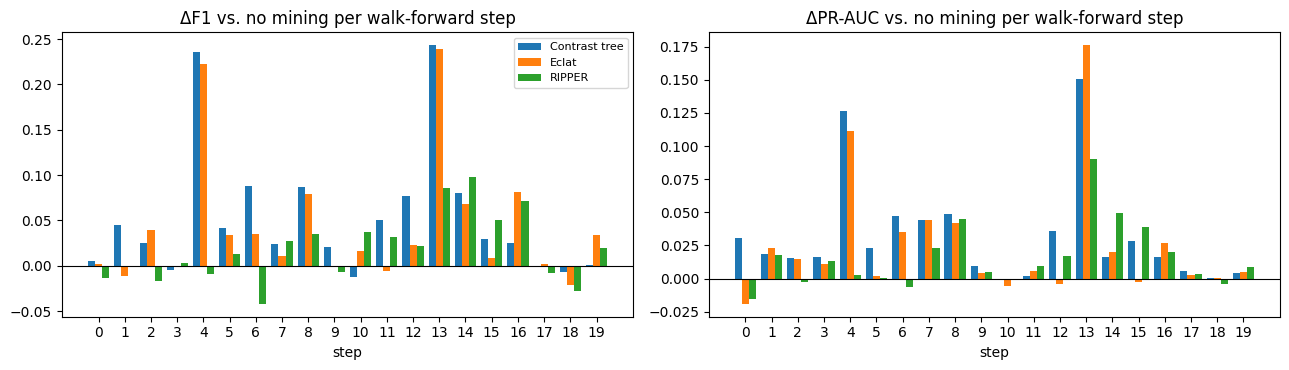

In [6]:
wide = {m: means.pivot(index="step_i", columns="arm", values=m) for m in ("f1", "pr_auc")}
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharex=True)
methods = [a for a in ARMS if a != "none"]
w = 0.27
for ax, (m, d) in zip(axes, wide.items()):
    for j, a in enumerate(methods):
        ax.bar(d.index + (j - 1) * w, d[a] - d["none"], width=w, color=COLOR[a], label=LABEL[a])
    ax.axhline(0, color="k", lw=0.8)
    ax.set_title(f"Δ{m.upper().replace('_', '-')} vs. no mining per walk-forward step")
    ax.set_xlabel("step"); ax.set_xticks(d.index)
axes[0].legend(fontsize=8)
plt.tight_layout()

## §3 Friedman test + Nemenyi critical difference

Steps are the blocks (seed-averaged). Rank 1 = best. Arms closer than CD in average rank are joined by a bar
(not significantly different at α = 0.05).

In [7]:
stats = {m: mc.friedman_nemenyi(per_step, m) for m in ("f1", "pr_auc")}
pd.DataFrame([{"metric": s["metric"], "chi2": s["friedman_chi2"], "p": s["friedman_p"], "CD": s["nemenyi_cd"],
               **{LABEL[a]: r for a, r in s["avg_rank"].items()}} for s in stats.values()])

,metric,chi2,p,CD,Contrast tree,Eclat,RIPPER,No mining
0,f1,11.10,0.011197,1.048803,1.85,2.30,2.7,3.15
1,pr_auc,20.82,0.000115,1.048803,1.65,2.45,2.4,3.50


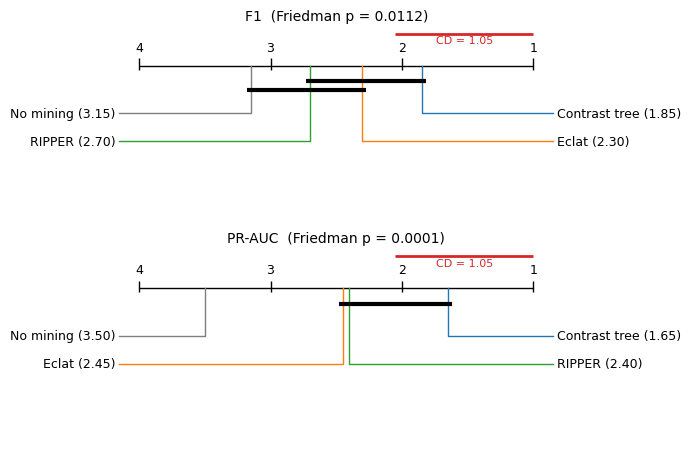

In [8]:
def cd_cliques(ranks: dict[str, float], cd: float) -> list[list[str]]:
    # Maximal groups of arms (in rank order) whose rank span is below CD.
    order = sorted(ranks, key=ranks.get)
    cliques = []
    for i in range(len(order)):
        j = i
        while j + 1 < len(order) and ranks[order[j + 1]] - ranks[order[i]] < cd:
            j += 1
        grp = order[i:j + 1]
        if len(grp) > 1 and not any(set(grp) <= set(c) for c in cliques):
            cliques.append(grp)
    return cliques


def cd_diagram(s: dict, ax) -> None:
    ranks, cd, k = s["avg_rank"], s["nemenyi_cd"], s["n_arms"]
    ax.set_xlim(k + 0.2, 0.8)  # rank 1 on the right
    ax.set_ylim(0, 1)
    ax.axis("off")
    ax.hlines(0.8, 1, k, color="k", lw=1)
    for r in range(1, k + 1):
        ax.vlines(r, 0.78, 0.84, color="k", lw=1)
        ax.text(r, 0.88, str(r), ha="center", fontsize=9)
    ax.hlines(0.97, 1, 1 + cd, color="tab:red", lw=2)
    ax.text(1 + cd / 2, 0.92, f"CD = {cd:.2f}", ha="center", fontsize=8, color="tab:red")
    order = sorted(ranks, key=ranks.get)
    half = (len(order) + 1) // 2
    for i, a in enumerate(order):
        right = i < half  # best arms labelled on the right
        y = 0.55 - 0.15 * (i if right else len(order) - 1 - i)
        xe = 0.85 if right else k + 0.15
        ax.plot([ranks[a], ranks[a], xe], [0.8, y, y], color=COLOR[a], lw=1)
        ax.text(xe + (-0.03 if right else 0.03), y, f"{LABEL[a]} ({ranks[a]:.2f})", va="center",
                ha="left" if right else "right", fontsize=9)
    for n, grp in enumerate(cd_cliques(ranks, cd)):
        lo, hi = min(ranks[a] for a in grp), max(ranks[a] for a in grp)
        ax.hlines(0.72 - 0.05 * n, lo - 0.03, hi + 0.03, color="k", lw=3)
    ax.set_title(f"{s['metric'].upper().replace('_', '-')}  (Friedman p = {s['friedman_p']:.4f})", fontsize=10)


fig, axes = plt.subplots(2, 1, figsize=(7, 4.6))
for ax, s in zip(axes, stats.values()):
    cd_diagram(s, ax)
plt.tight_layout()

## §4 Per-step scores

Seed-averaged F1 and PR-AUC per step; shading = min/max over seeds. Step size in test attacks for context.

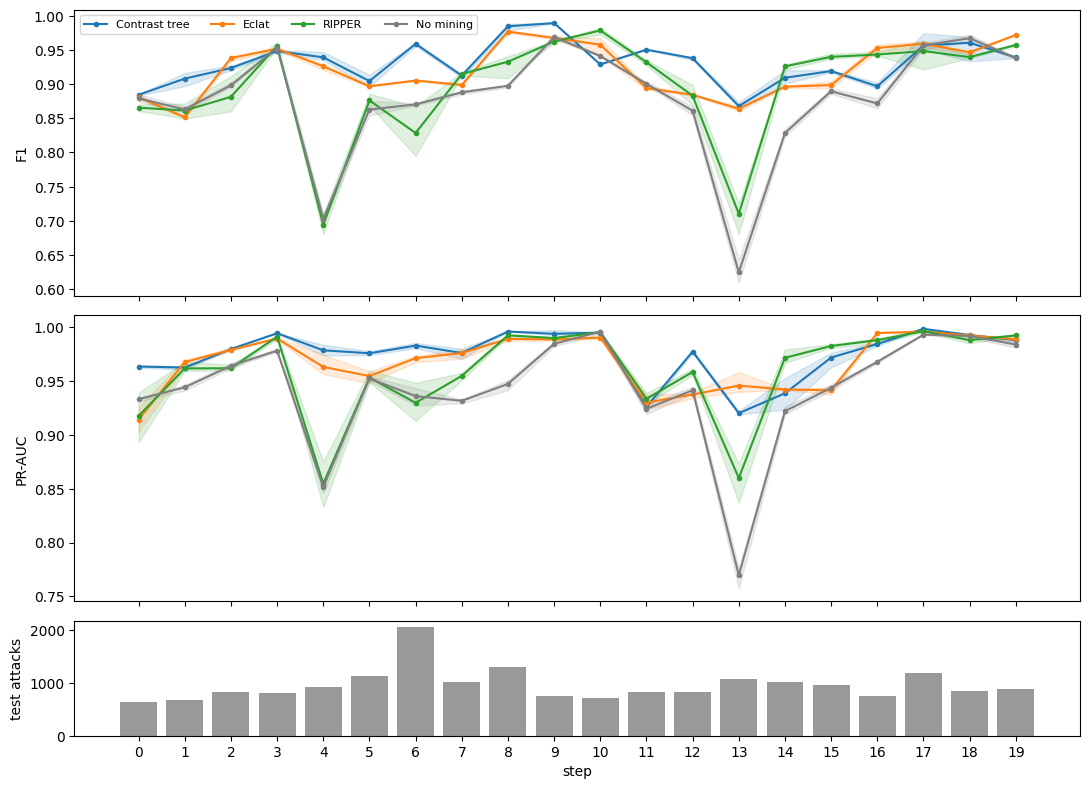

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True, gridspec_kw={"height_ratios": [3, 3, 1.2]})
for ax, m in zip(axes[:2], ("f1", "pr_auc")):
    for a in ARMS:
        g = per_step[per_step["arm"] == a].groupby("step_i")[m]
        ax.plot(g.mean().index, g.mean(), marker="o", ms=3, color=COLOR[a], label=LABEL[a])
        ax.fill_between(g.mean().index, g.min(), g.max(), color=COLOR[a], alpha=0.15)
    ax.set_ylabel(m.upper().replace("_", "-"))
axes[0].legend(fontsize=8, ncol=4)
att = per_step.groupby("step_i")["n_test_attack"].first()
axes[2].bar(att.index, att, color="0.6")
axes[2].set_ylabel("test attacks"); axes[2].set_xlabel("step")
axes[2].set_xticks(att.index)
plt.tight_layout()

## §5 Seed noise

Std over seeds within a step, averaged over steps. `none` and `eclat`/`contrast_tree` only vary through the RF seed;
RIPPER also re-mines per seed.

In [10]:
seed_sd = (per_step.groupby(["arm", "step_i"])[["f1", "pr_auc", "n_symbolic"]].std()
           .groupby("arm").mean().reindex(ARMS))
seed_sd.columns = [f"{c} seed-sd" for c in seed_sd.columns]
seed_sd

,f1 seed-sd,pr_auc seed-sd,n_symbolic seed-sd
arm,,,
contrast_tree,0.003885,0.002136,0.000000
eclat,0.002463,0.002775,0.000000
ripper,0.009015,0.004996,2.802365
none,0.003769,0.002413,0.000000


## §6 What the features look like

Per step (seed 0 for the stochastic miners): number of attack- vs. benign-leaning features after the budget, and the
number of conditions per feature.

In [11]:
f0 = features[features["mining_seed"].fillna(0) == features.groupby("arm")["mining_seed"].transform("min").fillna(0)]
lean = (f0.groupby(["arm", "step_i", "source_label"]).size().unstack(fill_value=0)
        .groupby("arm").mean().reindex([a for a in ARMS if a != "none"]))
lean.columns = [f"{c} / step" for c in lean.columns]
cond = (f0.groupby(["arm", "n_conditions"]).size().unstack(fill_value=0)
        .pipe(lambda d: d.div(d.sum(axis=1), axis=0)).reindex(lean.index))
cond.columns = [f"{c} cond." for c in cond.columns]
lean.join(cond)

,attack / step,benign / step,1 cond.,2 cond.,3 cond.,4 cond.,5 cond.,6 cond.,7 cond.,8 cond.,9 cond.,10 cond.
arm,,,,,,,,,,,,
contrast_tree,34.5,19.8,0.294659,0.615101,0.054328,0.035912,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
eclat,30.0,30.0,0.000000,0.000000,0.800833,0.199167,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
ripper,12.7,8.4,0.016588,0.194313,0.196682,0.104265,0.130332,0.146919,0.118483,0.056872,0.030806,0.004739


### Most persistent features

Conditions that are kept at the most steps (seed 0), per method.

In [12]:
TOP = 8
persist = (f0.groupby(["arm", "condition", "source_label"])["step_i"].nunique()
           .rename("steps").reset_index()
           .sort_values(["arm", "steps"], ascending=[True, False]))
for a in [a for a in ARMS if a != "none"]:
    print(f"\n== {LABEL[a]} ==")
    print(persist[persist["arm"] == a].head(TOP)[["steps", "source_label", "condition"]].to_string(index=False))


== Contrast tree ==
 steps source_label                               condition
    20       benign                            category=RPC
    20       benign                           category=SNMP
    20       benign          category=SNMP ∧ multi_ext_port
    20       benign            category=SNMP ∧ multi_target
    20       attack    category=WEB_SERVER ∧ multi_ext_port
    20       attack              category=WEB_SPECIFIC_APPS
    20       attack category=WEB_SPECIFIC_APPS ∧ ruleset=ET
    20       attack                             cve_present

== Eclat ==
 steps source_label                                          condition
    20       benign alert_count<=1 ∧ category=SNMP ∧ cve_age_years<=-1
    20       benign      alert_count<=1 ∧ cve_age_years<=-1 ∧ proto=17
    20       attack       alert_count<=1 ∧ cve_age_years<=-1 ∧ proto=6
    20       benign   alert_count<=1 ∧ cve_age_years<=-1 ∧ ruleset=GPL
    20       benign       category=SNMP ∧ cve_age_years<=-1 ∧ proto=17


### Which fields each method leans on

Share of a method's kept conditions that mention each field (seed 0, all steps). Signature-derived fields
(category, ruleset, …) are the candidates for the label shortcut checked by `--no-signature-items`.

In [13]:
import re

def field_of(item: str) -> str:
    # "NOT_category=DNS" -> category, "alert_count_gt_1.5" -> alert_count, "qualifier_possible" -> qualifier
    item = item.strip().removeprefix("NOT_")
    f = re.split(r"<=|>=|<|>|=|_gt_|_le_|_lt_|_ge_", item)[0]
    return "qualifier" if f.startswith("qualifier_") else f


def fields_of(cond: str) -> set[str]:
    return {field_of(p) for p in cond.split("∧")}

fx = f0.assign(field=f0["condition"].map(fields_of)).explode("field")
field_share = (fx.groupby(["arm", "field"]).size()
               .div(f0.groupby("arm").size(), level="arm")
               .unstack("arm").reindex(columns=[a for a in ARMS if a != "none"]).fillna(0))
field_share.sort_values("contrast_tree", ascending=False).round(3).head(15)

arm,contrast_tree,eclat,ripper
field,,,
category,0.436,0.250,0.668
ruleset,0.345,0.395,0.524
proto,0.322,0.515,0.647
multi_ext_port,0.155,0.187,0.244
qualifier,0.138,0.008,0.512
multi_target,0.119,0.123,0.318
signature_matches_per_day,0.109,0.410,0.524
cve_present,0.063,0.006,0.258
proto_mismatch,0.044,0.002,0.043


## Summary

Fill in after reading the run:
- **Mining helps** with every method; which beat `none` significantly on F1 / PR-AUC (§3)?
- **Between methods:** any significant difference at this number of steps?
- **Feature character:** size, conditions, redundancy, stability (§1, §6).
- **Unseen signatures:** which methods drop below `none` (§1)? Follow up with `--no-signature-items`.